In [1]:
# Exercice 6 : Apprentissage d'un RNN sur le corpus de texte Victor HUGO

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.callbacks import EarlyStopping

I0000 00:00:1791839516.645564  162055 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1791839516.696016  162055 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791839517.901761  162055 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [2]:
# 1. Chargement du corpus textuel depuis l'arborescence locale (dossier sources/)
# On lit le fichier ligne par ligne en ignorant les lignes vides
with open('sources/victor-hugo-texts.txt', 'r', encoding='utf-8') as f:
    texts = [line.strip() for line in f if line.strip() != '']

# Affichage de la première ligne pour vérifier que le chargement fonctionne
print(f"Exemple de texte : {texts[0]}")

Exemple de texte : Mes vers fuiraient


In [3]:
# 2. Tokenisation du corpus textuel (Transformation des mots en indices numériques)

# On définit la taille maximale du vocabulaire (on ne garde que les 1000 mots les plus fréquents)
vocab_size = 1000

# On définit la taille de la fenêtre contextuelle (par exemple 3 mots pour prédire le suivant)
window_size = 3

# Initialisation du Tokenizer de Keras avec la limite du vocabulaire
tokenizer = Tokenizer(num_words=vocab_size)

# fit_on_texts analyse tout le corpus pour recenser les mots et leur attribuer un identifiant unique (un entier)
tokenizer.fit_on_texts(texts)

# texts_to_sequences transforme chaque phrase textuelle en une suite d'entiers correspondant aux indices des mots
sequences = tokenizer.texts_to_sequences(texts)

In [4]:
# 3. Création des fenêtres d'entraînement pour le modèle RNN (Prédiction du mot suivant)
X = []
y = []

# Pour chaque phrase (séquence d'entiers) du corpus :
for seq in sequences:
    # On parcourt la séquence à partir du 1er mot pour créer des paires (Contexte -> Mot à prédire)
    for i in range(1, len(seq)):
        start_index = max(0, i - window_size)  # Prendre au plus les 3 derniers mots
        
        # X stocke les mots du contexte (la fenêtre de 3 mots maximum)
        X.append(seq[start_index:i])
        
        # y stocke le mot cible immédiat qui suit ce contexte
        y.append(seq[i])

# Harmonisation des séquences : pad_sequences complète avec des zéros au début (padding='pre') 
# pour que toutes les fenêtres d'entrée X aient exactement la même taille (window_size = 3)
X = pad_sequences(X, maxlen=window_size, padding='pre')

# Conversion de la liste cible y en tableau numpy exploitable par Keras
y = np.array(y)

# Affichage des dimensions finales des tenseurs d'entraînement
print(f"X shape: {X.shape}, y shape: {y.shape}")

X shape: (11541, 3), y shape: (11541,)


In [5]:
# 4. Construction et compilation du modèle RNN (Sequential API)
embedding_dim = 16

model = Sequential([
    # Couche Embedding : transforme chaque indice de mot en un vecteur dense de dimension 16
    Embedding(input_dim=vocab_size, output_dim=embedding_dim),
    
    # Couche SimpleRNN (32 neurones) : mémorise le contexte séquentiel des mots précédents
    SimpleRNN(32),
    
    # Couche de sortie Dense : autant de neurones que de mots dans le vocabulaire (1000)
    # L'activation 'softmax' renvoie une distribution de probabilités sur tous les mots possibles du dictionnaire
    Dense(vocab_size, activation='softmax')
])

# Compilation du modèle pour une classification multiclasse avec des entiers cibles
model.compile(loss='sparse_categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

# Affichage du résumé de l'architecture du RNN
model.summary()

E0000 00:00:1791839532.036985  162055 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [7]:
# 5. Entraînement du modèle RNN avec arrêt anticipé (EarlyStopping)
# On surveille la perte (loss) pour stopper l'apprentissage si elle ne s'améliore plus pendant 10 époques
early_stop = EarlyStopping(monitor='loss', patience=10, restore_best_weights=True)

history = model.fit(
    X, y,
    epochs=500,                         # Nombre maximal d'époques pour apprendre les enchaînements de mots
    batch_size=32,                      # Nombre d'exemples traités en parallèle
    callbacks=[early_stop],
    verbose=0
)

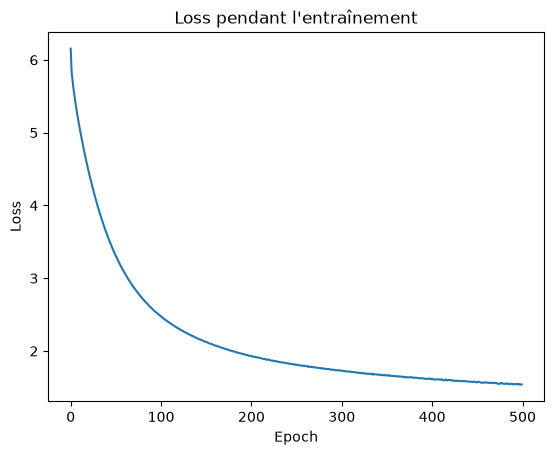

In [8]:
# 6. Visualisation de l'évolution de la fonction de perte (Loss) au cours de l'entraînement
plt.plot(history.history['loss'])
plt.title('Loss pendant l\'entraînement')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.show()

In [9]:
# 7. Fonction de génération de texte séquentiel avec le modèle RNN

def generate_text(start_text, num_words=50, temperature=0.8):
    text = start_text
    for _ in range(num_words):
        # Maintien du même format qu'à l'entraînement : extraction des 3 derniers mots uniquement
        tokens = tokenizer.texts_to_sequences([text])[0][-window_size:]
        tokens = pad_sequences([tokens], maxlen=window_size, padding='pre')
        
        # Prédiction des probabilités pour le mot suivant via le modèle
        probs = model.predict(tokens, verbose=0)[0]
        
        # Tirage pondéré avec la température (temp < 1 : plus sûr / prévisible, temp > 1 : plus varié / créatif)
        probs = np.exp(np.log(probs + 1e-9) / temperature)
        probs /= probs.sum()
        index = np.random.choice(len(probs), p=probs)
        
        # Récupération du mot correspondant à l'indice prédit
        word = tokenizer.index_word.get(index)
        if word is not None:  # L'indice 0 sert au bourrage (padding), ce n'est pas un mot valide
            text += ' ' + word
            
    return text

In [10]:
# 8. Test de génération à partir d'un mot d'amorce ("Poème") sur 50 mots
random_text = generate_text("Poème", num_words=50)
print(random_text)

Poème ce que tout ainsi à murmure nos roses dans chaque dans le qui se et s'en n'ont pas sans enfants alors travaille le seigneur j'ai sur une chiens sans me sans de de petits de broussailles à la chair s'est l'âme a si vis maintenant et quand à toi eux


In [11]:
# 9. Test d'un modèle amélioré avec une couche LSTM
from tensorflow.keras.layers import LSTM

# On garde la même dimension d'embedding (16)
embedding_dim = 16

# Construction du nouveau modèle séquentiel avec LSTM (64 neurones pour plus de capacité)
model = Sequential([
    Embedding(input_dim=vocab_size, output_dim=embedding_dim),
    LSTM(64),  # Remplacement du SimpleRNN par un LSTM plus performant pour la mémoire séquentielle
    Dense(vocab_size, activation='softmax')
])

# Compilation du modèle
model.compile(loss='sparse_categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

# Affichage de la nouvelle architecture
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [17]:
from tensorflow.keras.callbacks import Callback
from IPython.display import clear_output

# Redéfinition du callback pour le compteur dynamique
class LiveEpochUpdater(Callback):
    def on_epoch_end(self, epoch, logs=None):
        clear_output(wait=True)
        print(f"Époque en cours : {epoch + 1} | Loss : {logs.get('loss'):.4f}")

# Lancement de l'entraînement du modèle LSTM
history = model.fit(
    X, y,
    epochs=500,
    batch_size=32,
    callbacks=[early_stop, LiveEpochUpdater()],
    verbose=0
)

Époque en cours : 24 | Loss : 0.3894


In [18]:
# Test de génération avec notre nouveau modèle LSTM entraîné
random_text = generate_text("Poème", num_words=50)
print(random_text)

Poème sur le front du burgrave grave il une tombe les ils et vos but que cette à ma mère nous tu que vers là de tout car ce fait les lions toutes leurs va beau maître fleurs l'hiver je vous dis à va neveu de roi quand j'ai mon devant


In [19]:
# Test avec une température basse (plus rigide, plus répétitif ou prévisible)
print("--- Température : 0.2 ---")
print(generate_text("Poème", num_words=50, temperature=0.2))

--- Température : 0.2 ---
Poème comme un bruit de foule les que près le à la main et ses plaines du maître ô rêveur fleurs les le de tout et tout et chacun au et de la tête le et plus roule dans un charmants dans on vent du qui qui peut devant la forêt


In [20]:
# Test avec une température équilibrée
print("\n--- Température : 0.8 ---")
print(generate_text("Poème", num_words=50, temperature=0.8))


--- Température : 0.8 ---
Poème comme dans l'ombre avoir des où sont les que le sang dans le fleuve leurs sont de longs filets de sang voir le grand le seigneur plus ils de son casque est sous les ailes d'une hydre du je me rendra fou en deux on demande ce sont sous la


In [21]:
# Test avec une température élevée (plus créatif, mais risquant le chaos)
print("\n--- Température : 1.5 ---")
print(generate_text("Poème", num_words=50, temperature=1.5))


--- Température : 1.5 ---
Poème sur les murs un toit la bise sur ce toit des hideux aux eaux d'un fleuve et l'ombre casque du fanfare lui seul de et de dragons il les que pas il meute des rayons amours en proie tout ce qui m'a comme un fruit la forêt fer par le
